# Task 1 – Data Exploration Analysis
**AI305 Project – Saudi Arabia Used Cars**

In this notebook we:
1. Describe the data structure and every column
2. Find data issues (missing, duplicate, implausible values)
3. Compute descriptive statistics and check class balance
4. Study how each feature relates to **Price**
5. Study which features separate each **categorical** column (to choose classification targets)
6. Decide how to split the data into train and test sets

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # shared helpers live in src/common.py
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from common import (load_raw, clean_rows, NUMERIC, CATEGORICAL, FIG_DIR, RES_DIR,
                    MIN_PLAUSIBLE_PRICE, MAX_PLAUSIBLE_MILEAGE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data and look at its structure
The dataset is one CSV table: each row is one used-car ad on syarah.com. We use the original
(*unclean*) file with 8,248 rows so we can do the cleaning ourselves.

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
raw.head()

Shape: (8248, 15)


,Link,Make,Type,Year,Origin,Color,Options,Engine_Size,Fuel_Type,Gear_Type,Condition,Mileage,Region,Price,Negotiable
0,https://syarah.com/%D9%83%D8%B1%D8%A7%D9%8A%D8...,Chrysler,C300,2018,Saudi,Black,Full,5.7,Gas,Automatic,Used,103000,Riyadh,114000,False
1,https://syarah.com/%D9%86%D9%8A%D8%B3%D8%A7%D9...,Nissan,Patrol,2016,Saudi,White,Full,4.8,Gas,Automatic,Used,5448,Riyadh,Negotiable,True
2,https://syarah.com/online/%D9%86%D9%8A%D8%B3%D...,Nissan,Sunny,2019,Saudi,Silver,Standard,1.5,Gas,Automatic,Used,72418,Riyadh,27500,False
3,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Grey,Standard,1.6,Gas,Automatic,Used,114154,Riyadh,43000,False
4,https://syarah.com/online/%D9%87%D9%88%D9%86%D...,Hyundai,Elantra,2019,Saudi,Silver,Semi Full,2.0,Gas,Automatic,Used,41912,Riyadh,59500,False


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8248 entries, 0 to 8247
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Link         8248 non-null   str    
 1   Make         8248 non-null   str    
 2   Type         8248 non-null   str    
 3   Year         8248 non-null   int64  
 4   Origin       8153 non-null   str    
 5   Color        8248 non-null   str    
 6   Options      8139 non-null   str    
 7   Engine_Size  5982 non-null   float64
 8   Fuel_Type    8248 non-null   str    
 9   Gear_Type    8174 non-null   str    
 10  Condition    8248 non-null   str    
 11  Mileage      8248 non-null   int64  
 12  Region       8248 non-null   str    
 13  Price        8248 non-null   str    
 14  Negotiable   8248 non-null   bool   
dtypes: bool(1), float64(1), int64(2), str(11)
memory usage: 2.5 MB


### Column descriptions
| Column | Meaning |
|---|---|
| Link | URL of the ad (identifier) |
| Make | Brand, e.g. Toyota |
| Type | Car model, e.g. Camry |
| Year | Manufacturing year |
| Origin | Saudi / Gulf Arabic / Other (where the car was first sold) |
| Color | Exterior colour |
| Options | Trim level: Standard / Semi Full / Full |
| Engine_Size | Engine size in litres |
| Fuel_Type | Gas / Diesel / Hybrid |
| Gear_Type | Automatic / Manual |
| Condition | New / Used |
| Mileage | Kilometres driven |
| Region | City of the ad |
| Price | Price in SAR, or the text "Negotiable" |
| Negotiable | True if the seller accepts offers |

## 2. Data issues

In [4]:
# Missing values per column
raw.isna().sum()

Link              0
Make              0
Type              0
Year              0
Origin           95
Color             0
Options         109
Engine_Size    2266
Fuel_Type         0
Gear_Type        74
Condition         0
Mileage           0
Region            0
Price             0
Negotiable        0
dtype: int64

In [5]:
print("Condition values:", raw["Condition"].value_counts().to_dict())   # constant -> useless
print("Unique links:", raw["Link"].nunique(), "of", len(raw))           # identifier -> useless

Condition values: {'Used': 8248}
Unique links: 8228 of 8248


In [6]:
# Price is stored as text because some ads say "Negotiable"
neg = (raw["Price"] == "Negotiable").sum()
print(f"'Negotiable' prices: {neg} ({neg/len(raw):.1%})")
pd.crosstab(raw["Negotiable"], raw["Price"] == "Negotiable",
            rownames=["Negotiable flag"], colnames=["Price is 'Negotiable'"])

'Negotiable' prices: 2596 (31.5%)


Price is 'Negotiable',False,True
Negotiable flag,,
False,5652,0
True,0,2596


The `Negotiable` flag is True exactly when the price is missing, so it adds no extra information.

In [7]:
print("Duplicate rows (ignoring Link):", raw.drop(columns="Link").duplicated().sum())

# apply the rule-based cleaning from common.py: drop Link/Condition, Price text -> number (Negotiable -> 0),
# drop duplicates, impossible mileage -> NaN
df = clean_rows(raw)
print("Rows after cleaning:", len(df))

Duplicate rows (ignoring Link): 69
Rows after cleaning: 8179


In [8]:
# Implausible prices: tiny positive prices are monthly instalments, not car prices
low = df[(df.Price > 0) & (df.Price < MIN_PLAUSIBLE_PRICE)]
print("0 < Price < 5000:", len(low))
low.sort_values("Price")[["Make", "Type", "Year", "Mileage", "Price"]].head(10)

0 < Price < 5000: 96


,Make,Type,Year,Mileage,Price
8167,GMC,Yukon,2019,50000.0,1
7115,Genesis,G80,2018,170000.0,500
7761,Toyota,Yaris,2018,100000.0,850
2226,Mitsubishi,Attrage,2019,41000.0,877
3707,Kia,Rio,2019,55500.0,884
7358,Toyota,Yaris,2019,85000.0,950
1696,MG,5,2020,41000.0,988
7801,Hyundai,Elantra,2019,89000.0,993
3067,GMC,Yukon,2021,4000.0,1000
4348,Toyota,Corolla,2020,48563.0,1002


In [9]:
# Implausible mileage (already set to NaN by clean_rows) - look at the raw values
print("Mileage > 1,000,000 km:", (raw.Mileage > MAX_PLAUSIBLE_MILEAGE).sum())
print("Largest values:", sorted(raw.Mileage.nlargest(5).tolist()))
print("Very old cars (Year < 1980):", (df.Year < 1980).sum(), "-> rare but real classics, kept")

Mileage > 1,000,000 km: 45
Largest values: [4500000, 4691232, 4900000, 9999999, 20000000]
Very old cars (Year < 1980): 17 -> rare but real classics, kept


**Summary of issues and decisions**

| Issue | Decision |
|---|---|
| Price = "Negotiable" (31.5%) | Set to 0. Removed from regression (it is a missing target, not a real price) |
| 0 < Price < 5,000 SAR | Monthly instalments, removed from regression |
| Duplicate ads | Removed before the split (so no copy is in both train and test) |
| Mileage > 1,000,000 km | Impossible -> missing, imputed later |
| Engine_Size missing (27%) | Imputed with the median of the same car model, fitted on train only |
| Link, Condition | Dropped (identifier / constant) |

## 3. Descriptive statistics

In [10]:
num_cols = NUMERIC + ["Price"]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["missing"] = df[num_cols].isna().sum()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,missing
Year,8179.0,2014.01,5.94,1936.0,2012.0,2016.0,2018.0,2022.0,-2.62,0
Engine_Size,5925.0,3.18,1.57,1.0,2.0,2.7,4.0,9.0,0.95,2254
Mileage,8135.0,131825.41,123250.20,100.0,36350.0,101000.0,194000.0,1000000.0,1.49,44
Price,8179.0,53661.12,72885.67,0.0,0.0,36500.0,73000.0,1150000.0,3.57,0


In [11]:
priced = df[df.Price >= MIN_PLAUSIBLE_PRICE]
priced.Price.describe().round(0)

count       5497.0
mean       79811.0
std        76282.0
min         5000.0
25%        36000.0
50%        58000.0
75%        95000.0
max      1150000.0
Name: Price, dtype: float64

In [12]:
# Categorical features: number of values, most common value and imbalance
rows = []
for c in CATEGORICAL + ["Negotiable"]:
    vc = df[c].value_counts(dropna=False)
    rows.append({"feature": c, "n_unique": df[c].nunique(), "missing": int(df[c].isna().sum()),
                 "top": vc.index[0], "top_share": round(vc.iloc[0] / len(df), 3)})
pd.DataFrame(rows)

,feature,n_unique,missing,top,top_share
0,Make,65,0,Toyota,0.251
1,Type,435,0,Land Cruiser,0.045
2,Origin,3,95,Saudi,0.739
3,Color,15,0,White,0.433
4,Options,3,109,Full,0.392
5,Fuel_Type,3,0,Gas,0.976
6,Gear_Type,2,74,Automatic,0.856
7,Region,27,0,Riyadh,0.401
8,Negotiable,2,0,False,0.684


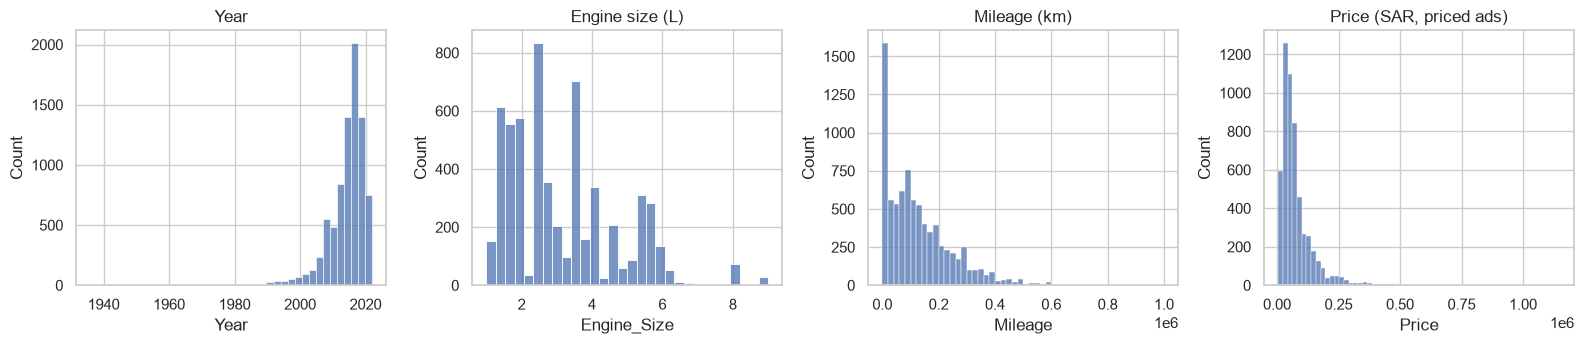

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
sns.histplot(df.Year, bins=40, ax=ax[0]).set_title("Year")
sns.histplot(df.Engine_Size.dropna(), bins=30, ax=ax[1]).set_title("Engine size (L)")
sns.histplot(df.Mileage.dropna(), bins=50, ax=ax[2]).set_title("Mileage (km)")
sns.histplot(priced.Price, bins=60, ax=ax[3]).set_title("Price (SAR, priced ads)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_numeric_distributions.png", dpi=130); plt.show()

Price and Mileage are strongly **right-skewed** (long tail of expensive / high-mileage cars). This is why we will train the regressors on log(Price).

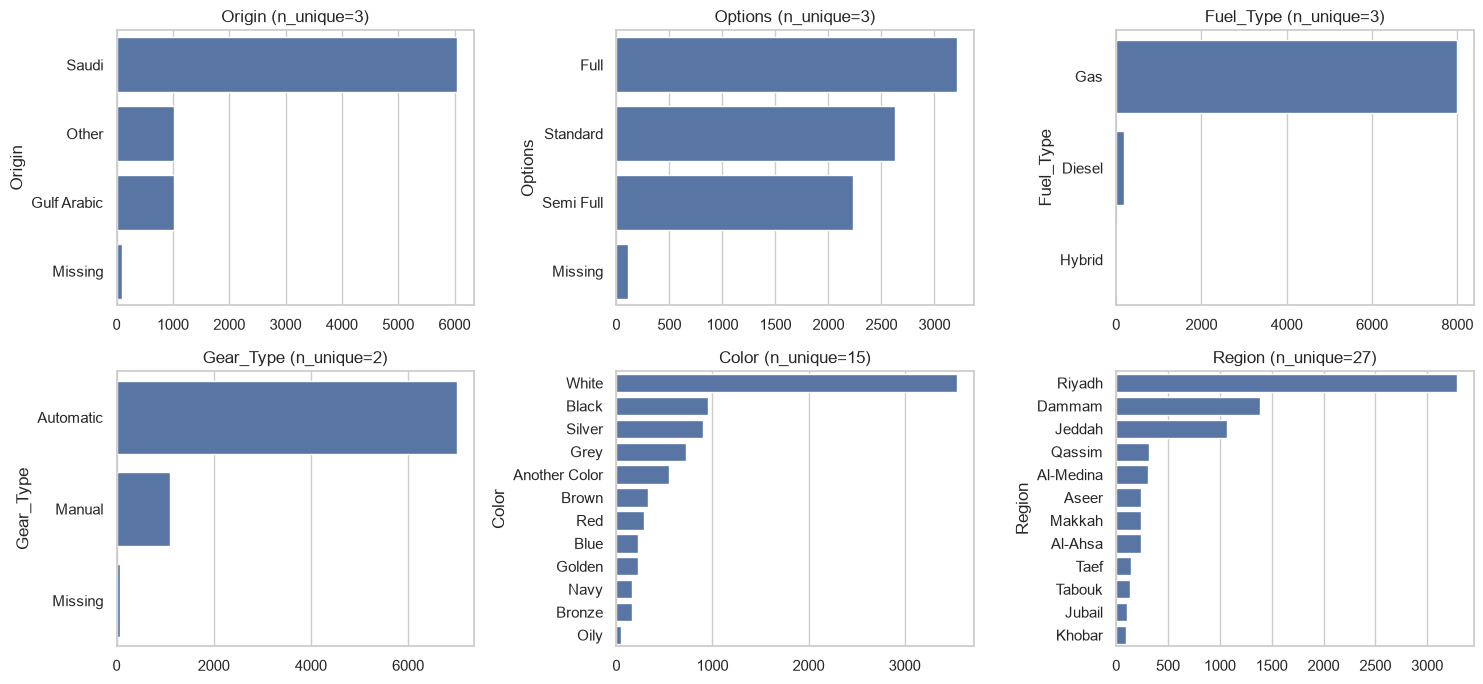

In [14]:
# Class balance of the categorical features
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), ["Origin", "Options", "Fuel_Type", "Gear_Type", "Color", "Region"]):
    vc = df[c].fillna("Missing").value_counts().head(12)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=a, color="#4C72B0")
    a.set_title(f"{c} (n_unique={df[c].nunique()})")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_categorical_balance.png", dpi=130); plt.show()

**Balance:** Fuel_Type is 97.6% Gas, Gear_Type is 86% Automatic, Riyadh has 40% of ads. Make and Type have
long tails of rare values. **Options** is the only fairly balanced column (≈39 / 33 / 28%).

## 4. Correlation and relationship with Price

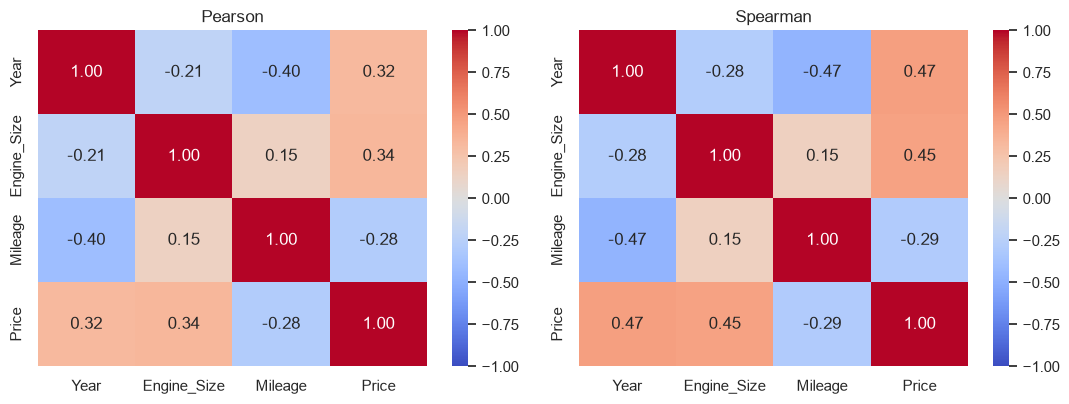

,pearson,spearman
Year,0.321,0.474
Engine_Size,0.340,0.454
Mileage,-0.282,-0.292


In [15]:
# use only priced ads with plausible values
p = df[(df.Price >= MIN_PLAUSIBLE_PRICE)].copy()
pear = p[num_cols].corr(method="pearson")
spear = p[num_cols].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(pear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]).set_title("Pearson")
sns.heatmap(spear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]).set_title("Spearman")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_correlation_heatmaps.png", dpi=130); plt.show()
pd.DataFrame({"pearson": pear["Price"], "spearman": spear["Price"]}).drop("Price").round(3)

We read **Spearman** because it is robust to skew and outliers: newer cars and bigger engines cost more, more mileage costs less.

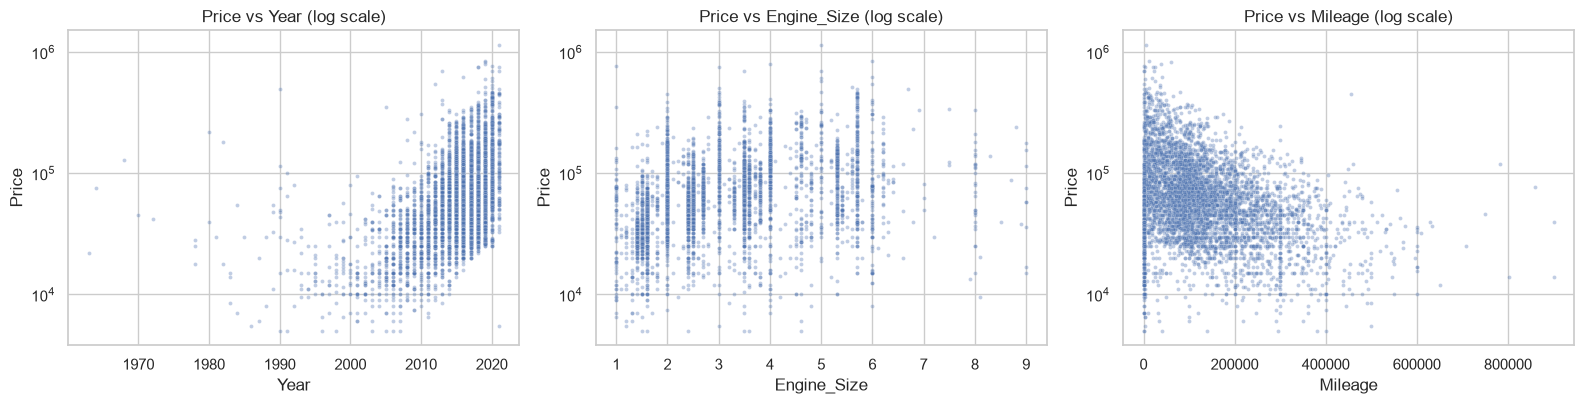

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, c in zip(ax, NUMERIC):
    sns.scatterplot(data=p, x=c, y="Price", s=8, alpha=0.35, ax=a)
    a.set_yscale("log"); a.set_title(f"Price vs {c} (log scale)")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_price_vs_numeric.png", dpi=130); plt.show()

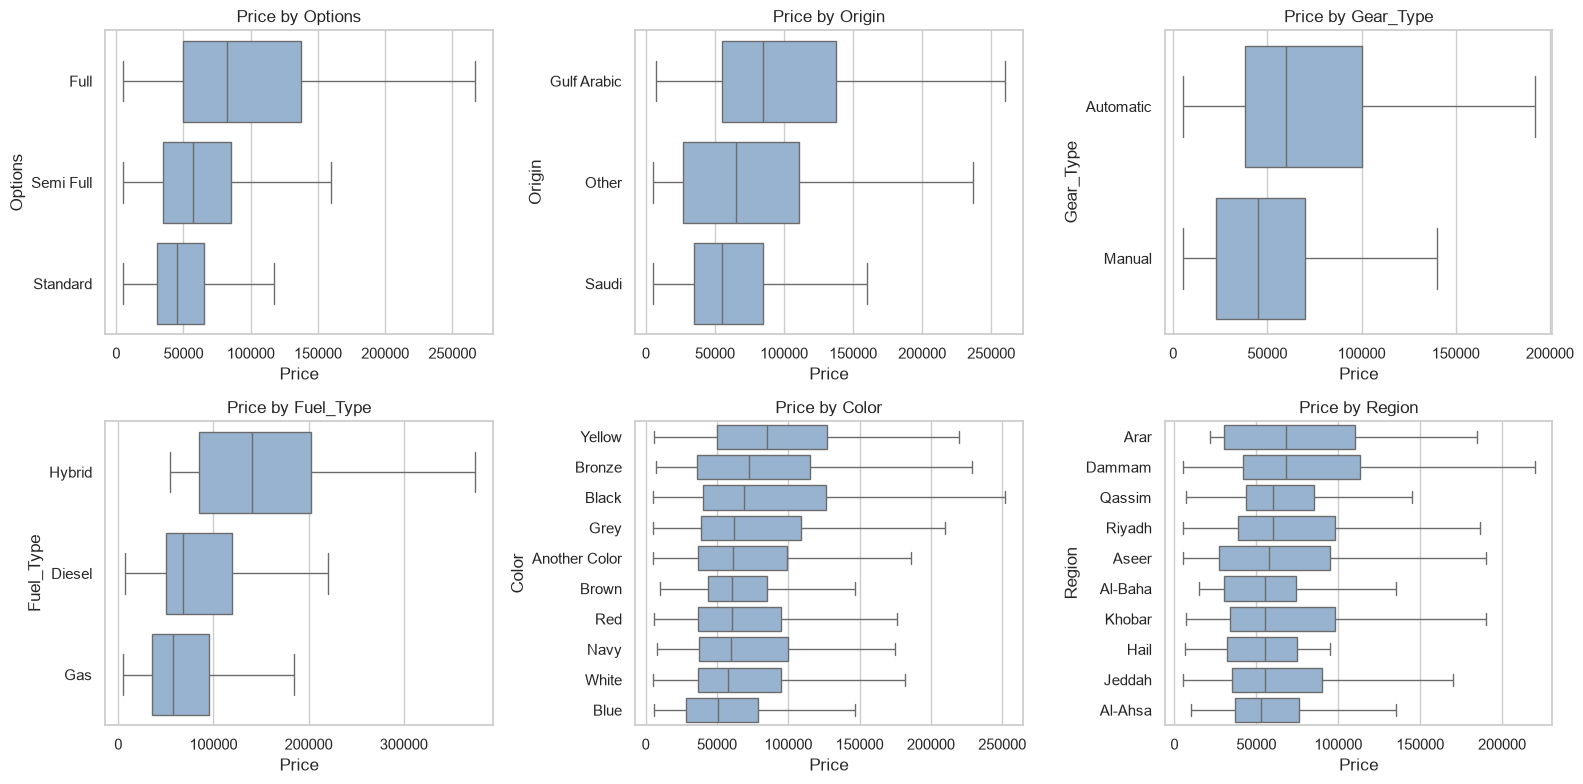

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), ["Options", "Origin", "Gear_Type", "Fuel_Type", "Color", "Region"]):
    order = p.groupby(c).Price.median().sort_values(ascending=False).index[:10]
    sns.boxplot(data=p[p[c].isin(order)], x="Price", y=c, order=order, ax=a, showfliers=False, color="#8FB3D9")
    a.set_title(f"Price by {c}")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_price_by_categorical.png", dpi=130); plt.show()

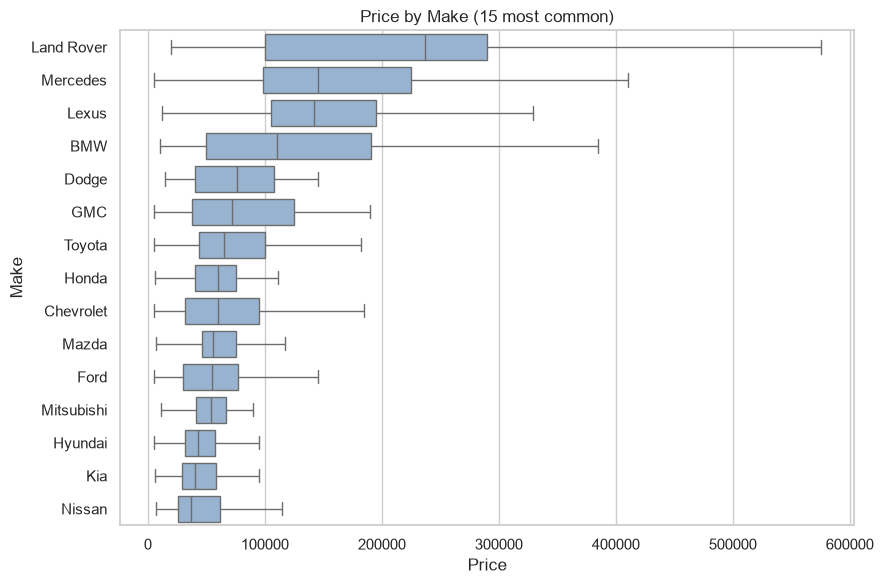

In [18]:
top = p.Make.value_counts().head(15).index
order = p[p.Make.isin(top)].groupby("Make").Price.median().sort_values(ascending=False).index
plt.figure(figsize=(9, 6))
sns.boxplot(data=p[p.Make.isin(top)], x="Price", y="Make", order=order, showfliers=False, color="#8FB3D9")
plt.title("Price by Make (15 most common)")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_price_by_make.png", dpi=130); plt.show()

In [19]:
def correlation_ratio(cat, num):
    """Eta: share of a numeric variable's variation explained by a categorical one (0..1)."""
    d = pd.DataFrame({"c": cat, "n": num}).dropna()
    grand = d["n"].mean()
    between = d.groupby("c")["n"].agg(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    total = ((d["n"] - grand) ** 2).sum()
    return float(np.sqrt(between / total))

effect = [{"feature": c, "association_with_price": round(correlation_ratio(p[c], p.Price), 3), "measure": "eta"}
          for c in CATEGORICAL]
effect += [{"feature": c, "association_with_price": round(abs(spear.loc[c, "Price"]), 3), "measure": "|Spearman|"}
           for c in NUMERIC]
pd.DataFrame(effect).sort_values("association_with_price", ascending=False)

,feature,association_with_price,measure
1,Type,0.767,eta
0,Make,0.607,eta
8,Year,0.474,|Spearman|
9,Engine_Size,0.454,|Spearman|
4,Options,0.336,eta
10,Mileage,0.292,|Spearman|
2,Origin,0.173,eta
3,Color,0.164,eta
7,Region,0.141,eta
6,Gear_Type,0.128,eta


In [20]:
print("Median price by Options:", p.groupby("Options").Price.median().to_dict())
print("Median price by Origin:", p.groupby("Origin").Price.median().to_dict())

Median price by Options: {'Full': 82250.0, 'Semi Full': 57000.0, 'Standard': 45000.0}
Median price by Origin: {'Gulf Arabic': 85000.0, 'Other': 65000.0, 'Saudi': 55000.0}


**Effect on price:** the car model (Type, η≈0.77) and Make (η≈0.61) explain most of the price, then Year,
Engine_Size, Options and Mileage. Origin, Color, Region, Gear_Type and Fuel_Type have only a weak effect on their own.

## 5. Which features separate each categorical column?
To choose the two classification targets we measure, for every categorical column, how strongly each other
feature is associated with it: **Cramér's V** for categorical inputs and **η** for numeric inputs (0 = none, 1 = perfect).

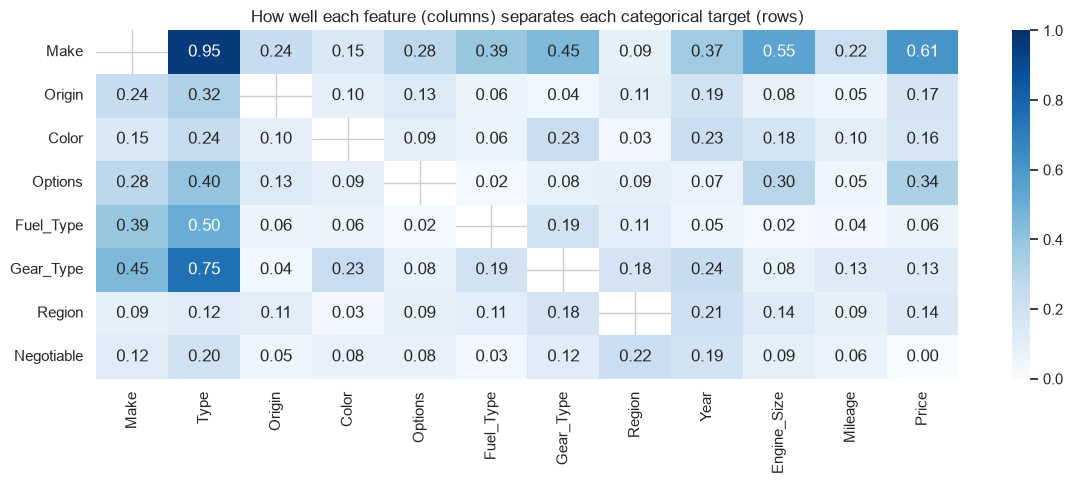

In [21]:
def cramers_v(x, y):
    t = pd.crosstab(x, y).to_numpy()
    n = t.sum()
    expected = t.sum(1, keepdims=True) @ t.sum(0, keepdims=True) / n
    chi2 = ((t - expected) ** 2 / np.where(expected == 0, 1, expected)).sum()
    r, k = t.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))          # bias-corrected
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    d = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2 / d)) if d > 0 else 0.0

targets = ["Make", "Origin", "Color", "Options", "Fuel_Type", "Gear_Type", "Region", "Negotiable"]
inputs = CATEGORICAL + NUMERIC + ["Price"]
d6 = df.copy()
d6.loc[d6.Price < MIN_PLAUSIBLE_PRICE, "Price"] = np.nan       # unpriced ads say nothing about price
mat = pd.DataFrame(index=targets, columns=inputs, dtype=float)
for t in targets:
    for f in inputs:
        if f == t:
            continue
        sub = d6[[t, f]].dropna()
        mat.loc[t, f] = correlation_ratio(sub[t], sub[f]) if f in NUMERIC + ["Price"] else cramers_v(sub[t], sub[f])

plt.figure(figsize=(12, 5))
sns.heatmap(mat.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("How well each feature (columns) separates each categorical target (rows)")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_categorical_target_association.png", dpi=130); plt.show()

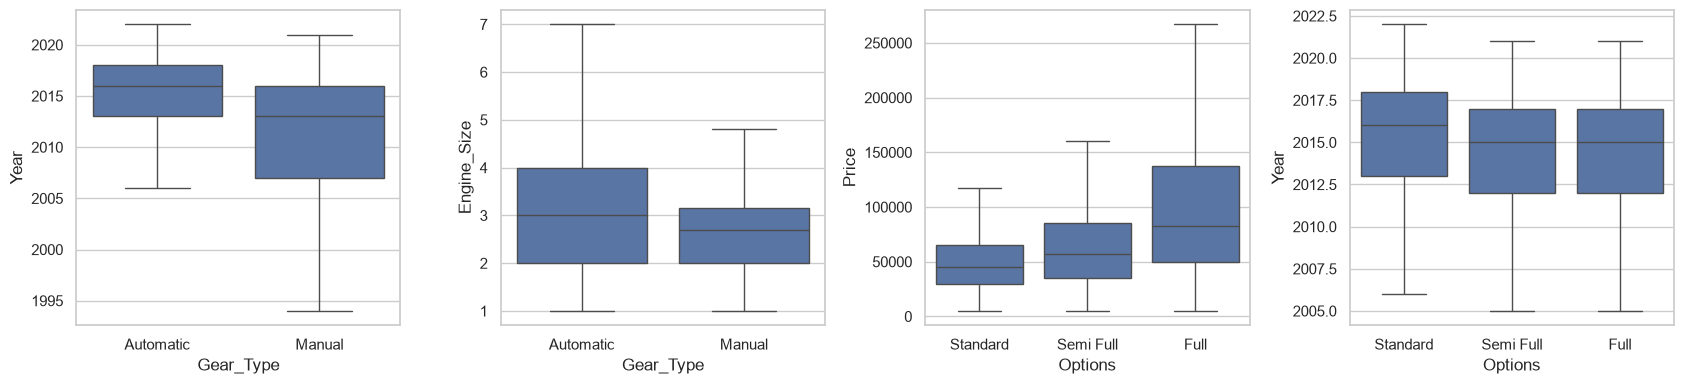

In [22]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
sns.boxplot(data=d6, x="Gear_Type", y="Year", ax=ax[0], showfliers=False)
sns.boxplot(data=d6, x="Gear_Type", y="Engine_Size", ax=ax[1], showfliers=False)
sns.boxplot(data=d6, x="Options", y="Price", ax=ax[2], showfliers=False, order=["Standard", "Semi Full", "Full"])
sns.boxplot(data=d6, x="Options", y="Year", ax=ax[3], showfliers=False, order=["Standard", "Semi Full", "Full"])
plt.tight_layout(); plt.savefig(FIG_DIR / "09_targets_boxplots.png", dpi=130); plt.show()

**Findings**
- **Gear_Type** is separated well by Type (0.75) and Make: some models (e.g. pickups) are often manual.
- **Options** is only weakly separated (best: Type 0.40, Price 0.34) → we expect it to be hard to classify.
- Make is almost determined by Type (0.95); Origin, Color, Region are close to unpredictable.

We choose **Gear_Type** (binary, imbalanced 86/14) and **Options** (3 balanced classes) as the two classification targets.

## 6. Train / test split
- 80% train / 20% test, `random_state=42`; stratified by the target for classification.
- Only the **rule-based** row cleaning above happens before the split.
- Everything that **learns** from data (imputation values, scaling, one-hot categories) is inside a scikit-learn
  `Pipeline`, so it is fitted on the training data only — also inside every cross-validation fold.
  This avoids data leakage.

The split itself is done at the start of the regression and classification notebooks.